In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [15]:
df = pd.read_csv("csv/cell_samples.csv")
df = df[pd.to_numeric(df['BareNuc'], errors='coerce').notnull()]
df['BareNuc'] = df['BareNuc'].astype(int)
df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc        int64
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

In [17]:
x = df.drop(columns=['ID'])
x = np.asarray(x)
x

array([[ 5,  1,  1, ...,  1,  1,  2],
       [ 5,  4,  4, ...,  2,  1,  2],
       [ 3,  1,  1, ...,  1,  1,  2],
       ...,
       [ 5, 10, 10, ..., 10,  2,  4],
       [ 4,  8,  6, ...,  6,  1,  4],
       [ 4,  8,  8, ...,  4,  1,  4]], shape=(683, 10))

In [18]:
from sklearn.preprocessing import StandardScaler
x_std = StandardScaler().fit_transform(x)
x_std

array([[ 0.19790469, -0.70221201, -0.74177362, ..., -0.61292736,
        -0.34839971, -0.73368133],
       [ 0.19790469,  0.27725185,  0.26278299, ..., -0.28510482,
        -0.34839971, -0.73368133],
       [-0.51164337, -0.70221201, -0.74177362, ..., -0.61292736,
        -0.34839971, -0.73368133],
       ...,
       [ 0.19790469,  2.23617957,  2.2718962 , ...,  2.33747554,
         0.22916583,  1.36298958],
       [-0.15686934,  1.58320366,  0.93248739, ...,  1.02618536,
        -0.34839971,  1.36298958],
       [-0.15686934,  1.58320366,  1.6021918 , ...,  0.37054027,
        -0.34839971,  1.36298958]], shape=(683, 10))

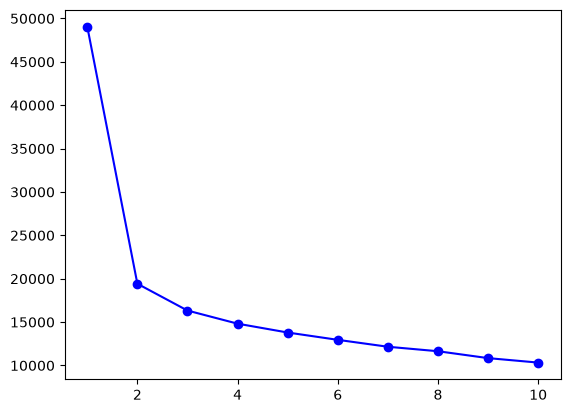

In [21]:
from sklearn.cluster import KMeans
wcss = []
k_value = range(1, 11)
for k in k_value:
    k_means = KMeans(init = 'k-means++', n_clusters = k, n_init = 12)
    k_means.fit(x)
    wcss.append(k_means.inertia_)

plt.plot(k_value, wcss,'bo-')

In [49]:
k_means = KMeans(init = 'k-means++', n_clusters = 2, n_init = 12)
k_means.fit(x_std)
labels = k_means.labels_
centers = k_means.cluster_centers_

In [50]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
x_2d = pca.fit_transform(x_std)
centers_2d = pca.transform(centers)

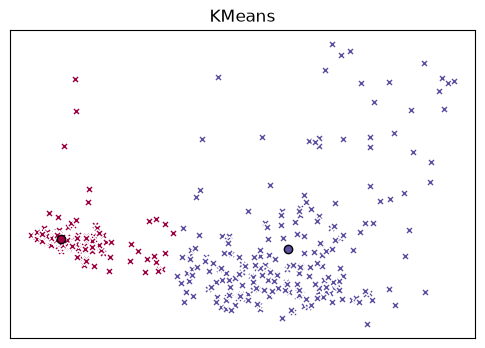

In [51]:
# Initialize the plot with the specified dimensions.
fig = plt.figure(figsize=(6, 4))

# Colors uses a color map, which will produce an array of colors based on
# the number of labels there are. We use set(k_means_labels) to get the
# unique labels.
colors = plt.cm.Spectral(np.linspace(0, 1, len(set(labels))))

# Create a plot
ax = fig.add_subplot(1, 1, 1)

# For loop that plots the data points and centroids.
# k will range from 0-3, which will match the possible clusters that each
# data point is in.
for k, col in zip(range(len(centers)), colors):

    # Create a list of all data points, where the data points that are 
    # in the cluster (ex. cluster 0) are labeled as true, else they are
    # labeled as false.
    my_members = (labels == k)
    
    # Define the centroid, or cluster center.
    cluster_center = centers_2d[k]
    
    # Plots the datapoints with color col.
    ax.plot(x_2d[my_members, 0], x_2d[my_members, 1], 'w', markerfacecolor=col, marker='X')
    
    # Plots the centroids with specified color, but with a darker outline
    ax.plot(cluster_center[0], cluster_center[1], 'o', markerfacecolor=col,  markeredgecolor='k', markersize=6)

# Title of the plot
ax.set_title('KMeans')

# Remove x-axis ticks
ax.set_xticks(())

# Remove y-axis ticks
ax.set_yticks(())

# Show the plot
plt.show()
